In [1]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, pandas as pd
from memoria_icm.datos import *
from memoria_icm.graficos import *
from memoria_icm.funciones import *
from memoria_icm.funciones_OU import *
from scipy.optimize import minimize
from scipy.stats import gaussian_kde

In [5]:
df, df_resumen = cargar_datos()
df = df[(df['especie'] == 'CC') & (df['tratamiento'] == 'R')]
variable = 'v_angular'
df = estimar_sigma_OU(df, variable)
df = estimar_alpha_mu_OU(df, variable)
df['salinidad'] = df['salinidad'].astype(str)

Datos cargados. Trackeo: (44324, 28), Resumen: (192, 42)


In [6]:
n_filas_a_eliminar = 30

df_filtrado = (
    df.groupby('id', group_keys=False, observed=True)
      .apply(lambda x: x.iloc[n_filas_a_eliminar:])
)

df_filtrado

df = df_filtrado

C:\Users\franc\AppData\Local\Temp\ipykernel_20492\4247245743.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.iloc[n_filas_a_eliminar:])


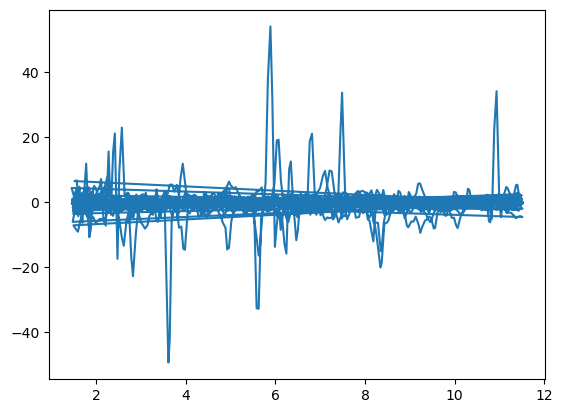

In [7]:
df
x = df['v_angular'].values
t = df['t'].values

plt.plot(t,x)

## Prueba de los métodos con una trayectoria simulada

alpha_hat: 1.2218748336691028
omega_inf_hat: 0.5115432485697047
sigma_hat: 0.31271575010804464


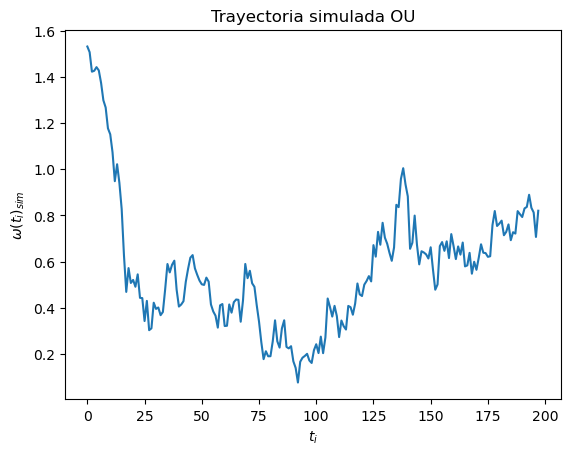

In [4]:
#simulación de prueba para ver si los métodos se portan bien
np.random.seed(150)
dt = 0.05
trayectorias_df, ids_df = extraer_trayectorias(df, variable)
longitud_minima_comun = min(len(r) for r, _ in trayectorias_df) - 1

omega0_vals = np.array([r[0] for r, _ in trayectorias_df])
kde_omega0 = gaussian_kde(omega0_vals)
x_grid = np.linspace(min(omega0_vals), max(omega0_vals), 1000)
pdf_vals  = kde_omega0(x_grid)
pdf_vals /= pdf_vals.sum() #normalizar

def sample_omega0():
            return np.random.choice(x_grid, p = pdf_vals)

omega0_sim = sample_omega0()
alpha = 1.2
omega_infinito = 0.5
sigma = 0.3

omega_sim = simular_OU(longitud_minima_comun, dt, alpha, omega_infinito, sigma, omega0_sim)
plt.plot(omega_sim, color = paleta_colores['R'])
plt.title('Trayectoria simulada OU')
plt.ylabel(r'$\omega(t_i)_{sim}$')
plt.xlabel(r'$t_i$')
#guardar_figura('trayectoria_simulada_OU', 'trayectorias de prueba simuladas')

#cálculo de sigma por variación cuadrática
dr = np.diff(omega_sim)
numerador = np.sum(dr**2)        # Σ (Δrₖ)²
denominador = len(dr) * dt
sigma2_hat = numerador / denominador if denominador > 0 else np.nan
sigma_hat = np.sqrt(sigma2_hat) if np.isfinite(sigma2_hat) else np.nan

#cálculo de alpha y r_infinito mediante OLS - fórmula del paper
df_tmp = pd.DataFrame({'v_angular': omega_sim, 't': np.arange(len(omega_sim)) * dt, 'id': 'sim'})
df_out = estimar_alpha_mu_OU(df_tmp, variable)
alpha_hat = df_out[df_out['id'] == 'sim']['alpha_hat'].iloc[0]
omega_infinito_hat    = df_out[df_out['id'] == 'sim']['mu_hat'].iloc[0]

print(f"alpha_hat: {alpha_hat}")
print(f"omega_inf_hat: {omega_infinito_hat}")
print(f"sigma_hat: {sigma_hat}")

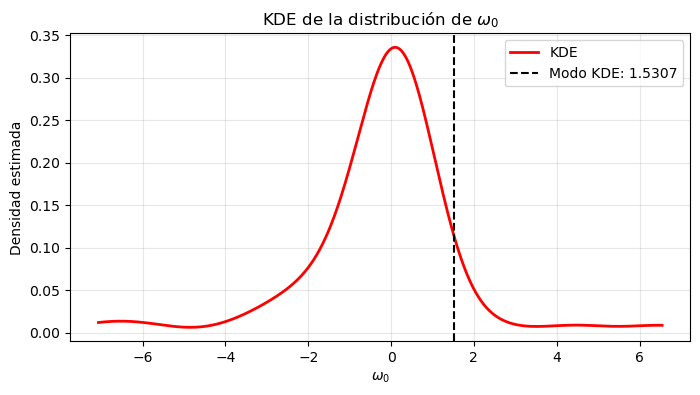

In [5]:
dens = kde_omega0(x_grid)
omega0_mode = omega0_sim

plt.figure(figsize=(8, 4))
plt.plot(x_grid, dens, color='red', lw=2, label='KDE')
plt.axvline(
    omega0_mode,
    color='black',
    linestyle='--',
    lw=1.5,
    label=f'Modo KDE: {omega0_mode:.4f}'
)
plt.xlabel(r"$\omega_0$")
plt.ylabel("Densidad estimada")
plt.title(r"KDE de la distribución de $\omega_0$")
plt.legend()
plt.grid(alpha=0.3)
#guardar_figura('KDE_omega0', 'trayectorias de prueba simuladas')
plt.show()

In [6]:
initial_guess = [alpha_hat, omega_infinito_hat]

res = minimize(
    fun=logverosimilitud_OU,
    x0=initial_guess,
    args=(omega_sim, dt, sigma_hat),
    method='Nelder-Mead'
)

#resultados
params_opt = res.x
func_val_opt = res.fun
success = res.success
message = res.message

# Comparación con valores reales
params_real = np.array([alpha, omega_infinito])
error_abs = np.abs(params_opt - params_real)
error_rel = error_abs / params_real

# Mostrar resultados
print("Parámetros estimados:      ", params_opt)
print("Parámetros reales:         ", params_real)
print("Error absoluto:            ", error_abs)
print("Error relativo (%):        ", 100 * error_rel)
print("Valor función objetivo:    ", func_val_opt)
print("¿Convergió exitosamente?:  ", success)
print("Mensaje del optimizador:   ", message)


Parámetros estimados:       [1.22187483 0.51154325]
Parámetros reales:          [1.2 0.5]
Error absoluto:             [0.02187483 0.01154325]
Error relativo (%):         [1.82290281 2.30864971]
Valor función objetivo:     -250.50717314483518
¿Convergió exitosamente?:   True
Mensaje del optimizador:    Optimization terminated successfully.


In [7]:
# #acá solo testeamos qué porcentaje de los parámetros son válidos, pero no eliminamos nada
# df_filtrado = df[(df['alpha_hat'] > 0) & 
#                  (df['sigma_hat'] > 0) &
#                  (~df['alpha_hat'].isna()) &
#                  (~df['sigma_hat'].isna())]

# ids_total = df['id'].nunique()
# ids_filtrados = df_filtrado['id'].nunique()
# descartadas = ids_total - ids_filtrados
# porc_descartado = 100 * descartadas / ids_total


# print(f"Trayectorias totales:         {ids_total}")
# print(f"Trayectorias válidas:         {ids_filtrados}")
# print(f"Trayectorias descartadas:     {descartadas}")
# print(f"Porcentaje descartado:        {porc_descartado:.2f}%")

In [8]:
# valid_ids = [42, 43, 46, 48, 50, 52, 53, 54, 55, 57, 58, 59, 60, 61, 63, 68, 69, 70, 71, 73, 74, 75, 76, 77, 78, 79, 80, 81, 83, 184, 185, 186, 188, 189, 190, 191, 195, 196, 197, 198, 200, 202, 203, 204, 205, 206]
# df_filtrado = df_filtrado[df_filtrado['id'].isin(valid_ids)].copy()

# print(df_filtrado['id'].nunique())

In [9]:
df = df_filtrado

# Aplicación a los grupos considerados

## Optimización y visualización

In [8]:
###PLOT 3D
import warnings
warnings.filterwarnings('ignore')

resultados_todos = []
trayectorias_all = {}

grupos = df[['especie', 'tratamiento', 'salinidad']].drop_duplicates().to_records(index=False)

for especie, tratamiento, salinidad in grupos:
    df_grp = filtrar_grupo_salinidad(df, especie, tratamiento, salinidad)
    trayectorias, ids = extraer_trayectorias(df_grp, variable)

    parametros_grupo = (
        df_grp.groupby('id')[['alpha_hat', 'mu_hat', 'sigma_hat']]
        .first()
        .reset_index()
    )

    parametros_grupo[['alpha_hat', 'mu_hat']] = parametros_grupo[['alpha_hat', 'mu_hat']].clip(lower=1e-10)
    #esto va o no?
    
    ids_filtrados, trayectorias_filtradas = zip(*[
        (i, t) for i, t in zip(ids, trayectorias)
        if i in parametros_grupo['id'].values
    ])
    
    for id_tray, (data, dt) in zip(ids_filtrados, trayectorias_filtradas):
        trayectorias_all[id_tray] = (data, dt)

    param_dict = parametros_grupo.set_index('id')[['alpha_hat', 'mu_hat', 'sigma_hat']].to_dict('index')

    resultados = []
    for id_tray, (data, dt) in zip(ids_filtrados, trayectorias_filtradas):
        sigma = param_dict[id_tray]['sigma_hat']
        x0 = np.array((param_dict[id_tray]['alpha_hat'], param_dict[id_tray]['mu_hat']))

        puntos = []
        def wrapped_cost(x):
            val = logverosimilitud_OU(x, data, dt, sigma)
            puntos.append((x.copy(), val))
            return val

        res = minimize(
            fun=wrapped_cost,
            x0=x0,
            method='Nelder-Mead',
        )

        alpha, mu = res.x
        
        resultados.append({
            'id':            id_tray,
            'alpha':         alpha,
            'mu':            mu,
            'sigma':         sigma,
            'valor_funcion': res.fun,
            'exito':         res.success,
            'mensaje':       res.message,
            'r0':            data[0]})
        

        alpha_list = [p[0][0] for p in puntos]
        mu_list   = [p[0][1] for p in puntos]

        alpha_min = min(alpha_list)
        alpha_max = max(alpha_list)
        mu_min    = min(mu_list)
        mu_max    = max(mu_list)

        epsilon_alpha = max(0.2 * (alpha_max - alpha_min), 1e-3)
        epsilon_mu    = max(0.2 * (mu_max - mu_min), 1e-3)

        alpha_min -= epsilon_alpha
        alpha_max += epsilon_alpha
        mu_min    -= epsilon_mu
        mu_max    += epsilon_mu

        alpha_vals = np.linspace(alpha_min, alpha_max, 50)
        mu_vals    = np.linspace(mu_min, mu_max, 50)
        
    #     #2D
    #     A_grid, M_grid = np.meshgrid(alpha_vals, mu_vals)
    #     Z = np.zeros_like(A_grid)

    #     for i in range(A_grid.shape[0]):
    #         for j in range(A_grid.shape[1]):
    #             params = [A_grid[i, j], M_grid[i, j]]
    #             Z[i, j] = logverosimilitud_OU(params, data, dt, sigma)
        
    #     plt.figure(figsize=(8, 6))
    #     contour = plt.contourf(A_grid, M_grid, Z, levels=50, cmap='viridis')
    #     plt.colorbar(contour, label=r"$\log(L)$")
        
    #     points = np.array([p for p, _ in puntos])        
    #     plt.plot(points[:, 0], points[:, 1], marker='o', color='red', markersize=3, linewidth=1, label="Trayectoria")
    #     plt.scatter(x0[0], x0[1], color='white', edgecolor = 'black', s=100, label="Punto inicial")
    #     plt.scatter(alpha, mu, color='gold', edgecolor = 'black', s=100, label="Mínimo encontrado")

    #     plt.xlabel(r'$\alpha$')
    #     plt.ylabel(r'$r_\infty$')
    #     plt.title(f"{especie}-{tratamiento}-{salinidad} - id: {id_tray}")
    #     plt.legend()
    #     guardar_figura(f"{especie}-{tratamiento}-{salinidad}-{id_tray}", 'opti2D_OU_FINAL')
    #     plt.show()

    #     # 3D
    #     from mpl_toolkits.mplot3d import Axes3D
    #     from matplotlib import cm

    #     fig = plt.figure(figsize=(10, 8))
    #     ax = fig.add_subplot(111, projection='3d')

    #     # Superficie de la función de verosimilitud
    #     surf = ax.plot_surface(A_grid, M_grid, Z, cmap=cm.viridis,
    #                            linewidth=0, antialiased=True, alpha=0.6)

    #     # Trayectoria de la optimización
    #     puntos_trayectoria_x = [p[0][0] for p in puntos]
    #     puntos_trayectoria_y = [p[0][1] for p in puntos]
    #     puntos_trayectoria_z = [p[1] for p in puntos]
    #     ax.plot(puntos_trayectoria_x, puntos_trayectoria_y, puntos_trayectoria_z,
    #             marker='o', color='red', markersize=3, linestyle='-', linewidth=2, label="Trayectoria")

    #     # Punto inicial
    #     ax.scatter(x0[0], x0[1], wrapped_cost(x0), color='white', edgecolor= 'black', s=100, zorder=5, label="Punto inicial")

    #     # Mínimo encontrado
    #     ax.scatter(alpha, mu, res.fun, color='gold', edgecolor = 'black', s=100, zorder=5, label="Mínimo encontrado")
    #     ax.set_xlabel(r'$\alpha$')
    #     ax.set_ylabel(r'$r_\infty$')
    #     ax.set_title(f"{especie}-{tratamiento}-{salinidad} - id: {id_tray}")
    #     fig.colorbar(surf, shrink=0.5, aspect=5)
    #     ax.legend()
    #     guardar_figura(f"{especie}-{tratamiento}-{salinidad}-{id_tray}", 'opti3D_OU_FINAL')
    #     plt.show()

    df_res = pd.DataFrame(resultados)
    df_res['grupo'] = f"{especie}-{tratamiento}-{salinidad}"
    resultados_todos.append(df_res)

df_todos = pd.concat(resultados_todos, ignore_index=True)

In [9]:
df_todos

,id,alpha,mu,sigma,valor_funcion,exito,mensaje,r0,grupo
0,42,4.641684,1.090681e-10,6.421488,330.416967,True,Optimization terminated successfully.,-1.141496,CC-R-35-N
1,43,17.438672,9.063446e-11,26.856455,561.369741,True,Optimization terminated successfully.,-0.476715,CC-R-35-N
2,45,23.562168,2.496860e-01,11.458414,327.096907,True,Optimization terminated successfully.,0.602317,CC-R-35-N
3,46,135.543851,4.115729e-01,6.342340,91.268517,True,Optimization terminated successfully.,0.492775,CC-R-35-N
4,48,4.984821,1.079840e-10,14.778298,511.662668,True,Optimization terminated successfully.,-0.035064,CC-R-35-R
5,50,1595.774421,1.296885e-01,6.385960,-152.218086,True,Optimization terminated successfully.,0.577828,CC-R-35-R
6,51,2551.996641,9.556891e-03,10.772156,-96.016168,True,Optimization terminated successfully.,-0.228447,CC-R-35-R
7,52,6001.650231,3.891140e-02,7.494660,-253.931170,True,Optimization terminated successfully.,-0.092241,CC-R-35-R
8,53,8.292188,1.011233e-10,13.362402,423.476367,True,Optimization terminated successfully.,-2.275818,CC-R-35-R
9,54,225.605228,8.378538e-02,5.019210,-4.748723,True,Optimization terminated successfully.,0.114497,CC-R-40


In [11]:
df

,index,id,t,x,y,id_ubicacion,especie,tratamiento,salinidad,nombre_archivo,...,v_angular,a_angular,theta_v,curvatura,duracion_video_recortada,nivel_salinidad,sigma2_hat,sigma_hat,alpha_hat,mu_hat
15048,15048,82,3.038514,1.628673,-0.417834,1,CC,R,60,Video_005,...,0.804554,0.136365,-0.402983,0.622779,11.515,alta,236.376734,15.374548,15.051569,0.516313
15049,15049,82,3.077434,1.635815,-0.420894,1,CC,R,60,Video_005,...,0.641486,-4.741320,-0.435642,17.179650,11.515,alta,236.376734,15.374548,15.051569,0.516313
15050,15050,82,3.127350,1.640167,-0.423354,1,CC,R,60,Video_005,...,0.369513,-1.444387,-0.505471,3.538980,11.515,alta,236.376734,15.374548,15.051569,0.516313
15051,15051,82,3.203466,1.647033,-0.427033,1,CC,R,60,Video_005,...,0.724334,1.877105,-0.210534,46.723494,11.515,alta,236.376734,15.374548,15.051569,0.516313
15052,15052,82,3.238991,1.654005,-0.428041,1,CC,R,60,Video_005,...,0.744851,-0.096469,-0.185521,19.063021,11.515,alta,236.376734,15.374548,15.051569,0.516313
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15213,15213,82,11.306590,1.883980,-0.089760,1,CC,R,60,Video_005,...,0.835300,1.745306,1.890455,7.368724,11.515,alta,236.376734,15.374548,15.051569,0.516313
15214,15214,82,11.376170,1.876175,-0.062442,1,CC,R,60,Video_005,...,0.984856,-0.710596,1.912647,5.846535,11.515,alta,236.376734,15.374548,15.051569,0.516313
15215,15215,82,11.426290,1.870321,-0.048782,1,CC,R,60,Video_005,...,0.845987,1.391378,2.222228,32.740040,11.515,alta,236.376734,15.374548,15.051569,0.516313
15216,15216,82,11.465770,1.861540,-0.040977,1,CC,R,60,Video_005,...,1.030355,2.817997,2.113097,34.008744,11.515,alta,236.376734,15.374548,15.051569,0.516313


In [10]:
df_todos = df_todos[~df_todos['alpha'].isnull()]
df_todos

,id,alpha,mu,sigma,valor_funcion,exito,mensaje,r0,grupo
0,42,4.641684,1.090681e-10,6.421488,330.416967,True,Optimization terminated successfully.,-1.141496,CC-R-35-N
1,43,17.438672,9.063446e-11,26.856455,561.369741,True,Optimization terminated successfully.,-0.476715,CC-R-35-N
2,45,23.562168,2.496860e-01,11.458414,327.096907,True,Optimization terminated successfully.,0.602317,CC-R-35-N
3,46,135.543851,4.115729e-01,6.342340,91.268517,True,Optimization terminated successfully.,0.492775,CC-R-35-N
4,48,4.984821,1.079840e-10,14.778298,511.662668,True,Optimization terminated successfully.,-0.035064,CC-R-35-R
5,50,1595.774421,1.296885e-01,6.385960,-152.218086,True,Optimization terminated successfully.,0.577828,CC-R-35-R
6,51,2551.996641,9.556891e-03,10.772156,-96.016168,True,Optimization terminated successfully.,-0.228447,CC-R-35-R
7,52,6001.650231,3.891140e-02,7.494660,-253.931170,True,Optimization terminated successfully.,-0.092241,CC-R-35-R
8,53,8.292188,1.011233e-10,13.362402,423.476367,True,Optimization terminated successfully.,-2.275818,CC-R-35-R
9,54,225.605228,8.378538e-02,5.019210,-4.748723,True,Optimization terminated successfully.,0.114497,CC-R-40


## De acá en adelante es sobre un grupo particular

In [34]:
import warnings
warnings.filterwarnings('ignore')

grupo = 'CC-R'

filtro = df_todos[df_todos['grupo'].str.startswith(grupo)].copy()
filtro['salinidad'] = filtro['grupo'].str[5:]
orden_salinidad = sorted(filtro['salinidad'].unique(), key=lambda x: str(x))
filtro['salinidad_ordenada'] = pd.Categorical(filtro['salinidad'], categories=orden_salinidad, ordered=True)

In [35]:
filtro

,id,alpha,mu,sigma,valor_funcion,exito,mensaje,r0,grupo,salinidad,salinidad_ordenada
0,42,4.641684,1.090681e-10,6.421488,330.416967,True,Optimization terminated successfully.,-1.141496,CC-R-35-N,35-N,35-N
1,43,17.438672,9.063446e-11,26.856455,561.369741,True,Optimization terminated successfully.,-0.476715,CC-R-35-N,35-N,35-N
2,45,23.562168,2.496860e-01,11.458414,327.096907,True,Optimization terminated successfully.,0.602317,CC-R-35-N,35-N,35-N
3,46,135.543851,4.115729e-01,6.342340,91.268517,True,Optimization terminated successfully.,0.492775,CC-R-35-N,35-N,35-N
4,48,4.984821,1.079840e-10,14.778298,511.662668,True,Optimization terminated successfully.,-0.035064,CC-R-35-R,35-R,35-R
5,50,1595.774421,1.296885e-01,6.385960,-152.218086,True,Optimization terminated successfully.,0.577828,CC-R-35-R,35-R,35-R
6,51,2551.996641,9.556891e-03,10.772156,-96.016168,True,Optimization terminated successfully.,-0.228447,CC-R-35-R,35-R,35-R
7,52,6001.650231,3.891140e-02,7.494660,-253.931170,True,Optimization terminated successfully.,-0.092241,CC-R-35-R,35-R,35-R
8,53,8.292188,1.011233e-10,13.362402,423.476367,True,Optimization terminated successfully.,-2.275818,CC-R-35-R,35-R,35-R
9,54,225.605228,8.378538e-02,5.019210,-4.748723,True,Optimization terminated successfully.,0.114497,CC-R-40,40,40


Figura guardada en: C:\Users\franc\Desktop\Para informe\plot_parametros_OU\parametros-CC-R.png


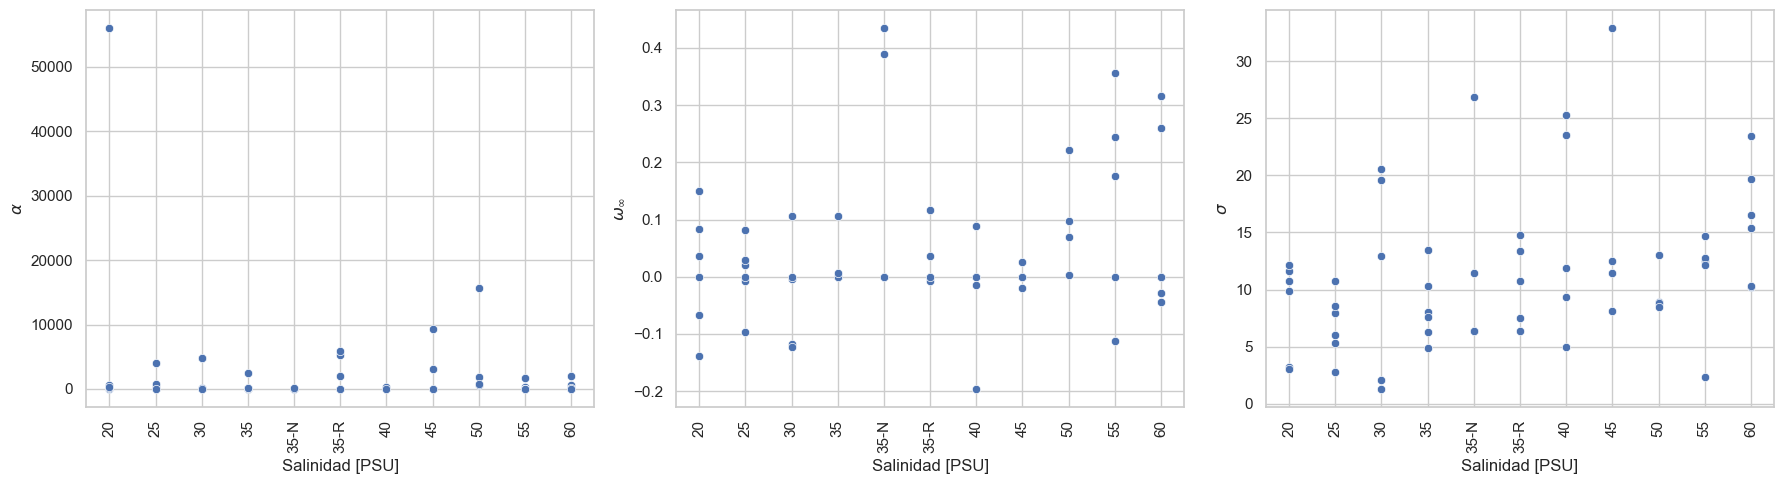

In [31]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

# alpha subplot
sns.scatterplot(data=filtro, x='salinidad_ordenada', y='alpha', ax=axs[0])
axs[0].set_ylabel(r'$\alpha$')
axs[0].set_xlabel('Salinidad [PSU]')

# mu subplot
sns.scatterplot(data=filtro, x='salinidad_ordenada', y='mu', ax=axs[1])
axs[1].set_ylabel(r'$\omega_{\infty}$')
axs[1].set_xlabel('Salinidad [PSU]')

# sigma subplot
sns.scatterplot(data=filtro, x='salinidad_ordenada', y='sigma', ax=axs[2])
axs[2].set_ylabel(r'$\sigma$')
axs[2].set_xlabel('Salinidad [PSU]')

# Rotate x-axis labels for better readability
for ax in axs:
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
guardar_figura(f'parametros-{grupo}', 'plot_parametros_OU')
plt.show()

In [13]:
#para quitar outliers y ver diferencia entre gráficos

def filtrar_outliers_IQR(df, columnas):
    df_filtrado = df.copy()
    for col in columnas:
        Q1 = df_filtrado[col].quantile(0.25)
        Q3 = df_filtrado[col].quantile(0.75)
        IQR = Q3 - Q1
        lim_inf = Q1 - 1.5 * IQR
        lim_sup = Q3 + 1.5 * IQR
        df_filtrado = df_filtrado[(df_filtrado[col] >= lim_inf) & (df_filtrado[col] <= lim_sup)]
    return df_filtrado

filtro_sin_outliers = filtrar_outliers_IQR(filtro, ['alpha', 'mu', 'sigma'])

Figura guardada en: C:\Users\franc\Desktop\Para informe\plot_parametros_OU_sin_outliers\parametros-CC-R.png


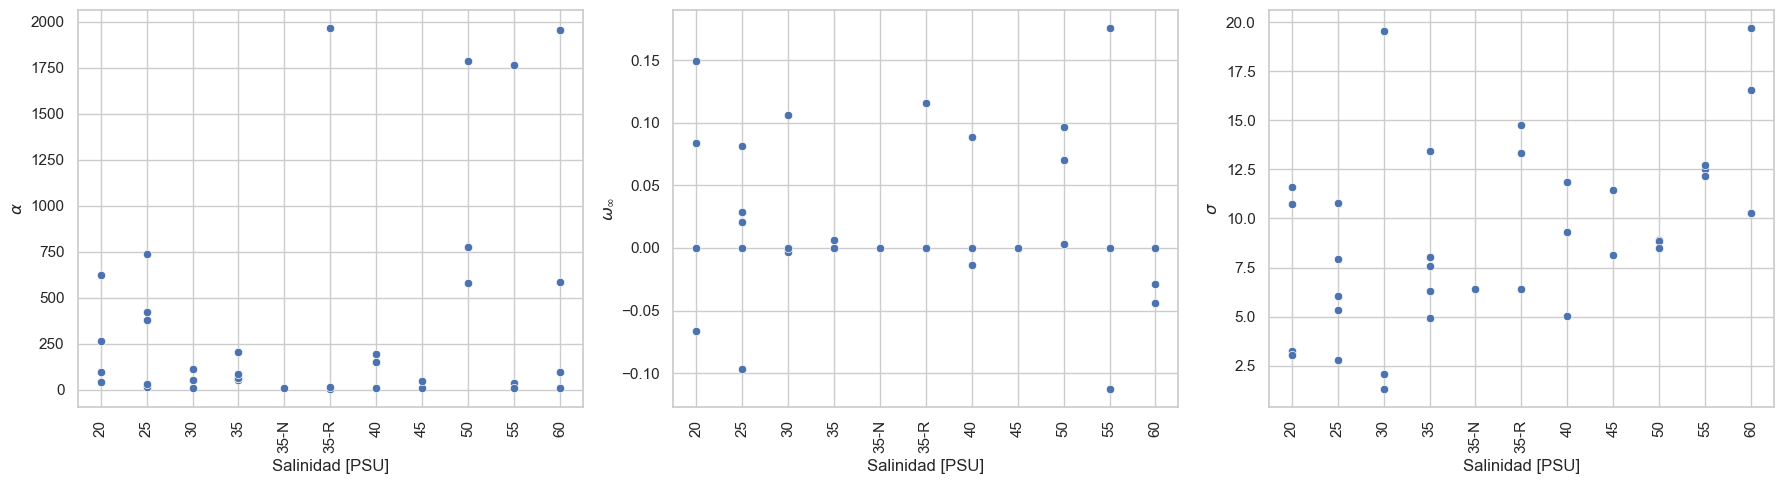

In [33]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

# alpha subplot
sns.scatterplot(data=filtro_sin_outliers, x='salinidad_ordenada', y='alpha', ax=axs[0])
axs[0].set_ylabel(r'$\alpha$')
axs[0].set_xlabel('Salinidad [PSU]')

# mu subplot
sns.scatterplot(data=filtro_sin_outliers, x='salinidad_ordenada', y='mu', ax=axs[1])
axs[1].set_ylabel(r'$\omega_{\infty}$')
axs[1].set_xlabel('Salinidad [PSU]')

# sigma subplot
sns.scatterplot(data=filtro_sin_outliers, x='salinidad_ordenada', y='sigma', ax=axs[2])
axs[2].set_ylabel(r'$\sigma$')
axs[2].set_xlabel('Salinidad [PSU]')

# Rotate x-axis labels for all subplots
for ax in axs:
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
guardar_figura(f'parametros-{grupo}', 'plot_parametros_OU_sin_outliers')
plt.show()

Figura guardada en: C:\Users\franc\Desktop\Para informe\plot_parametros_OU_sin_outliers\scatter_mu_alpha_sin_outliers_OU.png


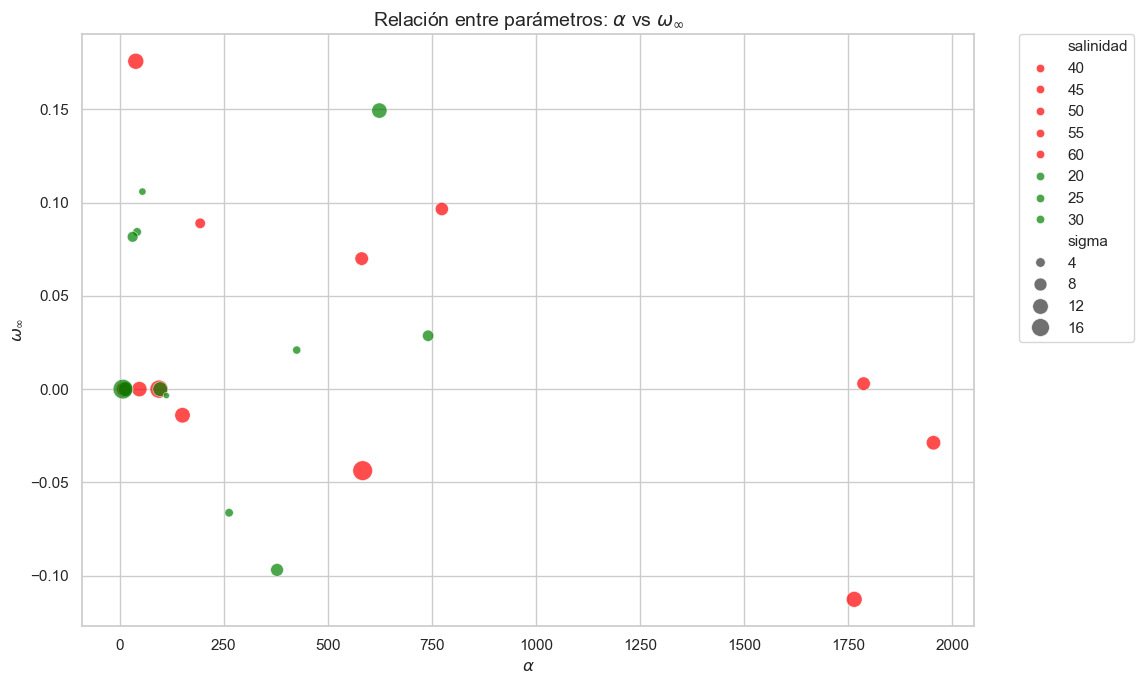

In [34]:
filtrofinal = filtro_sin_outliers[~filtro_sin_outliers['salinidad'].isin(['35', '35-N', '35-R'])]

# Configuración de estilo
sns.set(style="whitegrid")
paleta_salinidad = {
    "35-N": "blue",
    "35-R": "blue",
    "35": "blue",
    "20": "green",
    "25": "green",
    "30": "green",
    "40": "red",
    "45": "red",
    "50": "red",
    "55": "red",
    "60": "red"
}
# Gráfico de dispersión
plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(
    data=filtrofinal,
    x="alpha",
    y="mu",
    hue="salinidad",       # Color por salinidad
    size="sigma",          # Tamaño proporcional a sigma,         # Forma del marcador según éxito
    sizes=(20, 200),       # Rango de tamaños de puntos
    alpha=0.7,
    palette=paleta_salinidad
)

# Ajustes de leyenda y título
plt.title(r"Relación entre parámetros: $\alpha$ vs $\omega_{\infty}$", fontsize=14)
plt.xlabel(r"$\alpha$", fontsize=12)
plt.ylabel(r"$\omega_{\infty}$", fontsize=12)
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)  # leyenda afuera
guardar_figura('scatter_mu_alpha_sin_outliers_OU', 'plot_parametros_OU_sin_outliers')
plt.show()


In [56]:
# def evaluar_estimadores_OU_paper_una_trayectoria(simular_OU, trayectoria, dt, alpha, r_infinito, sigma, variable,
#                                                  especie, tratamiento, salinidad, id_actual, M=1000):
#     r_vals, dt_tray = trayectoria
#     N_rep = len(r_vals) - 1
#     r0 = r_vals[0]
#     sims = np.stack([simular_OU(N_rep, dt_tray, alpha, r_infinito, sigma, r0) for _ in range(M)])
#     percentiles = [np.percentile(sims, q, axis=0) for q in (0, 5, 50, 95, 100)]
#     p0, p5, p50, p95, p100 = percentiles
#     times = np.arange(N_rep + 1) * dt

#     puntos_dentro_banda = (r_vals >= p5) & (r_vals <= p95)
    
#     conteo_dentro = np.sum(puntos_dentro_banda)
#     conteo_total = len(r_vals)
#     porcentaje_dentro = (conteo_dentro / conteo_total) * 100
#     print(f"Grupo {especie}-{tratamiento}-{salinidad.upper()} - Porcentaje de tiempo dentro de la banda de 90%: {porcentaje_dentro:.2f}%")
    
#     fig, ax = plt.subplots(figsize=(10, 6))

#     #Dibuja en los ejes, no directamente con plt
#     ax.fill_between(times, p0, p100, color='lightgray', alpha=0.4, label='0–100% simuladas')
#     ax.fill_between(times, p5, p95, color='lightblue', alpha=0.4, label='Banda 90% simulada')
#     ax.plot(times, p50, 'b-', linewidth=2, label='Mediana simulada')
#     ax.plot(times, p5, '--', color='red', lw=1.5, label='5º percentil')
#     ax.plot(times, p95, '--', color='blue', lw=1.5, label='95º percentil')

#     r_trunc = r_vals[:N_rep + 1]
#     t_tray = np.arange(len(r_trunc)) * dt_tray
#     ax.plot(t_tray, r_trunc, color='black', linewidth=1.5, alpha=0.9, label=f"Trayectoria real")

#     ax.legend(loc='upper right')
#     ax.set_xlabel("Tiempo [s]")
#     ax.set_ylabel(variable)
#     ax.set_title(f"Grupo {especie}-{tratamiento}-{salinidad.upper()}")
#     ax.grid(True, alpha=0.3)
#     #guardar_figura(f'SIM_{especie}-{tratamiento}-{salinidad} - ID-{id_actual}', f'simulaciones_OU_{especie}-{tratamiento}_FINAL')
#     plt.show()

#     return porcentaje_dentro

In [57]:
def evaluar_estimadores_OU_paper_una_trayectoria(simular_OU, trayectoria, dt, alpha, r_infinito, sigma, variable,
                                                 especie, tratamiento, salinidad, id_actual, M=1000, T=11.515):
    r_vals, dt_tray = trayectoria
    N_rep = int(T / dt)  # número de pasos de la simulación
    r0 = r_vals[0]

    # Simulaciones en malla fina
    sims = np.stack([simular_OU(N_rep, dt, alpha, r_infinito, sigma, r0) for _ in range(M)])
    percentiles = [np.percentile(sims, q, axis=0) for q in (0, 5, 50, 95, 100)]
    p0, p5, p50, p95, p100 = percentiles
    times = np.arange(N_rep + 1) * dt

    # Tiempo de la trayectoria real
    t_tray = np.arange(len(r_vals)) * dt_tray

    # Interpolamos simulaciones a la malla real
    p0_interp  = np.interp(t_tray, times, p0)
    p5_interp  = np.interp(t_tray, times, p5)
    p50_interp = np.interp(t_tray, times, p50)
    p95_interp = np.interp(t_tray, times, p95)
    p100_interp= np.interp(t_tray, times, p100)

    # --- Cálculo del porcentaje de contención en la malla real ---
    puntos_dentro_banda = (r_vals >= p5_interp) & (r_vals <= p95_interp)
    conteo_dentro = np.sum(puntos_dentro_banda)
    conteo_total = len(r_vals)
    porcentaje_dentro = (conteo_dentro / conteo_total) * 100
    print(f"Grupo {especie}-{tratamiento}-{salinidad.upper()} - Porcentaje de tiempo dentro de la banda de 90%: {porcentaje_dentro:.2f}%")

    # --- Gráfico ---
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.fill_between(t_tray, p0_interp, p100_interp, color='lightgray', alpha=0.4, label='0–100% simuladas')
    ax.fill_between(t_tray, p5_interp, p95_interp, color='lightblue', alpha=0.4, label='Banda 90% simulada')
    ax.plot(t_tray, p50_interp, 'b-', linewidth=2, label='Mediana simulada')
    ax.plot(t_tray, p5_interp, '--', color='red', lw=1.5, label='5º percentil')
    ax.plot(t_tray, p95_interp, '--', color='blue', lw=1.5, label='95º percentil')

    # Trayectoria real
    ax.plot(t_tray, r_vals, color='black', linewidth=1.5, alpha=0.9, label=f"Trayectoria real")

    ax.legend(loc='upper right')
    ax.set_xlabel("Tiempo [s]")
    ax.set_ylabel(variable)
    ax.set_title(f"Grupo {especie}-{tratamiento}-{salinidad.upper()}")
    ax.grid(True, alpha=0.3)
    plt.show()

    return porcentaje_dentro


,id,alpha,mu,sigma,valor_funcion,exito,mensaje,r0,grupo,salinidad,salinidad_ordenada
0,42,4.641684,1.090681e-10,6.421488,330.416967,True,Optimization terminated successfully.,-1.141496,CC-R-35-N,35-N,35-N
1,43,17.438672,9.063446e-11,26.856455,561.369741,True,Optimization terminated successfully.,-0.476715,CC-R-35-N,35-N,35-N
2,45,23.562168,2.496860e-01,11.458414,327.096907,True,Optimization terminated successfully.,0.602317,CC-R-35-N,35-N,35-N
3,46,135.543851,4.115729e-01,6.342340,91.268517,True,Optimization terminated successfully.,0.492775,CC-R-35-N,35-N,35-N
4,48,4.984821,1.079840e-10,14.778298,511.662668,True,Optimization terminated successfully.,-0.035064,CC-R-35-R,35-R,35-R
5,50,1595.774421,1.296885e-01,6.385960,-152.218086,True,Optimization terminated successfully.,0.577828,CC-R-35-R,35-R,35-R
6,51,2551.996641,9.556891e-03,10.772156,-96.016168,True,Optimization terminated successfully.,-0.228447,CC-R-35-R,35-R,35-R
7,52,6001.650231,3.891140e-02,7.494660,-253.931170,True,Optimization terminated successfully.,-0.092241,CC-R-35-R,35-R,35-R
8,53,8.292188,1.011233e-10,13.362402,423.476367,True,Optimization terminated successfully.,-2.275818,CC-R-35-R,35-R,35-R
9,54,225.605228,8.378538e-02,5.019210,-4.748723,True,Optimization terminated successfully.,0.114497,CC-R-40,40,40


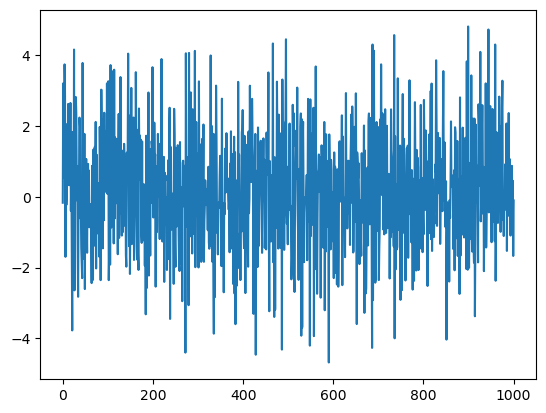

In [45]:
filtro = filtro[filtro['id'] == 82]
np.random.seed(0)
simulacion = simular_OU(1000, 0.011515, filtro['alpha'], filtro['mu'], filtro['sigma'], filtro['r0'])
plt.plot(simulacion)

In [58]:
filtro

,id,alpha,mu,sigma,valor_funcion,exito,mensaje,r0,grupo,salinidad,salinidad_ordenada
33,82,97.764695,0.248203,15.374548,294.970838,True,Optimization terminated successfully.,-0.16614,CC-R-60,60,60


Grupo CC-R-60 - Porcentaje de tiempo dentro de la banda de 90%: 100.00%


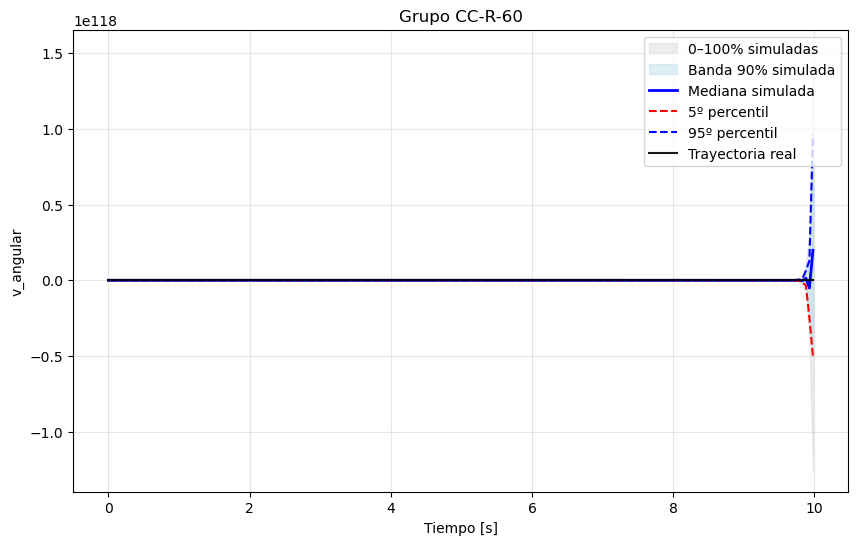

In [61]:
resultados_contencion = []

for index, fila in filtro.iterrows():
    
    id_actual = fila['id']
    
    if id_actual in trayectorias_all:
        trayectoria_real, dt_real = trayectorias_all[id_actual]
        porcentaje = evaluar_estimadores_OU_paper_una_trayectoria(
            simular_OU=simular_OU,
            trayectoria=(trayectoria_real, dt_real),
            dt=dt_real,
            alpha=fila['alpha'],
            r_infinito=fila['mu'],
            sigma=fila['sigma'],
            variable=variable,
            especie=fila['grupo'].split('-')[0],
            tratamiento=fila['grupo'].split('-')[1],
            salinidad=fila['grupo'].split('-')[2],
            id_actual = fila['id'],
            M=1000
        )
        
        resultados_contencion.append({
            'id': id_actual,
            'grupo': fila['grupo'],
            'porcentaje_contencion': porcentaje,
            'salinidad': fila['salinidad']
        })
    else:
        print(f"Advertencia: No se encontró la trayectoria original para el ID {id_actual}.")
        
df_contencion = pd.DataFrame(resultados_contencion)

### Histograma de los porcentajes de este grupo

In [38]:
df_contencion['salinidad_ordenada'] = pd.Categorical(df_contencion['salinidad'], categories=orden_salinidad, ordered=True)
print(df_contencion)

     id      grupo  porcentaje_contencion salinidad salinidad_ordenada
0    42  CC-R-35-N              95.930233      35-N               35-N
1    43  CC-R-35-N              97.687861      35-N               35-N
2    45  CC-R-35-N              96.491228      35-N               35-N
3    46  CC-R-35-N             100.000000      35-N               35-N
4    48  CC-R-35-R              95.348837      35-R               35-R
5    50  CC-R-35-R               0.584795      35-R               35-R
6    51  CC-R-35-R               0.574713      35-R               35-R
7    52  CC-R-35-R               0.581395      35-R               35-R
8    53  CC-R-35-R              94.705882      35-R               35-R
9    54    CC-R-40             100.000000        40                 40
10   55    CC-R-40             100.000000        40                 40
11   57    CC-R-40              94.767442        40                 40
12   58    CC-R-40             100.000000        40                 40
13   5

Figura guardada en: C:\Users\franc\Desktop\Para informe\porcentajes_contencion\histograma_porcentajes_contencion_OU.png
Figura guardada en: C:\Users\franc\Desktop\Para informe\porcentajes_contencion\boxplot_porcentaje_contencion_por_salinidad_OU.png


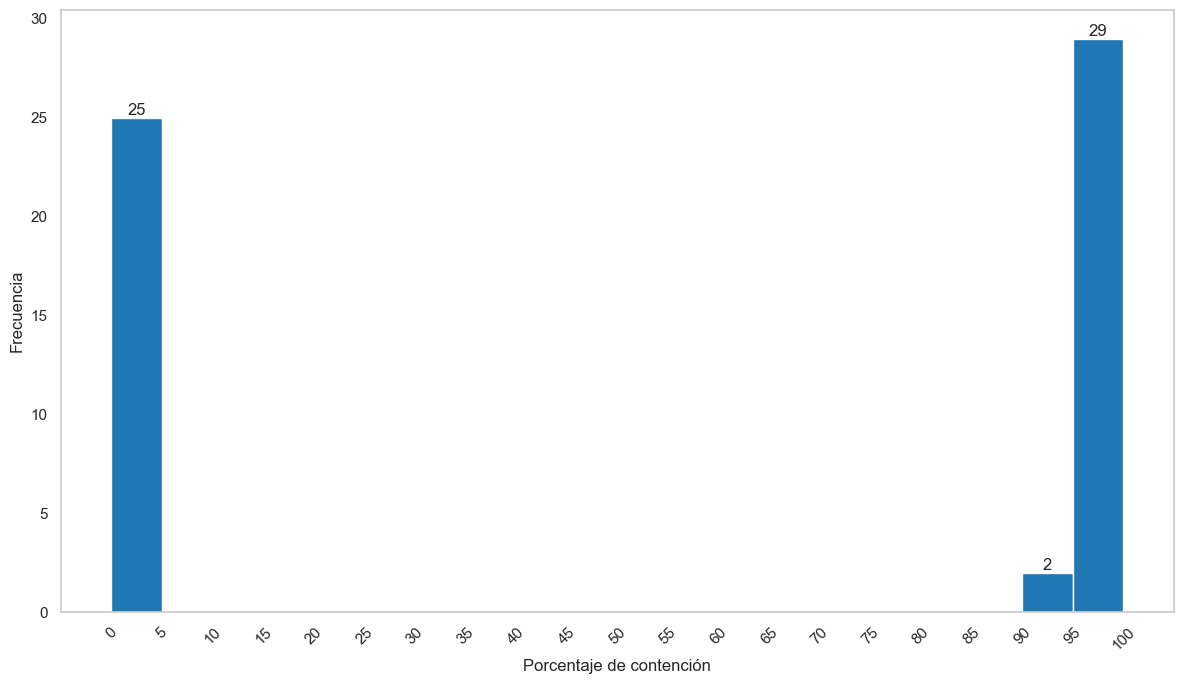

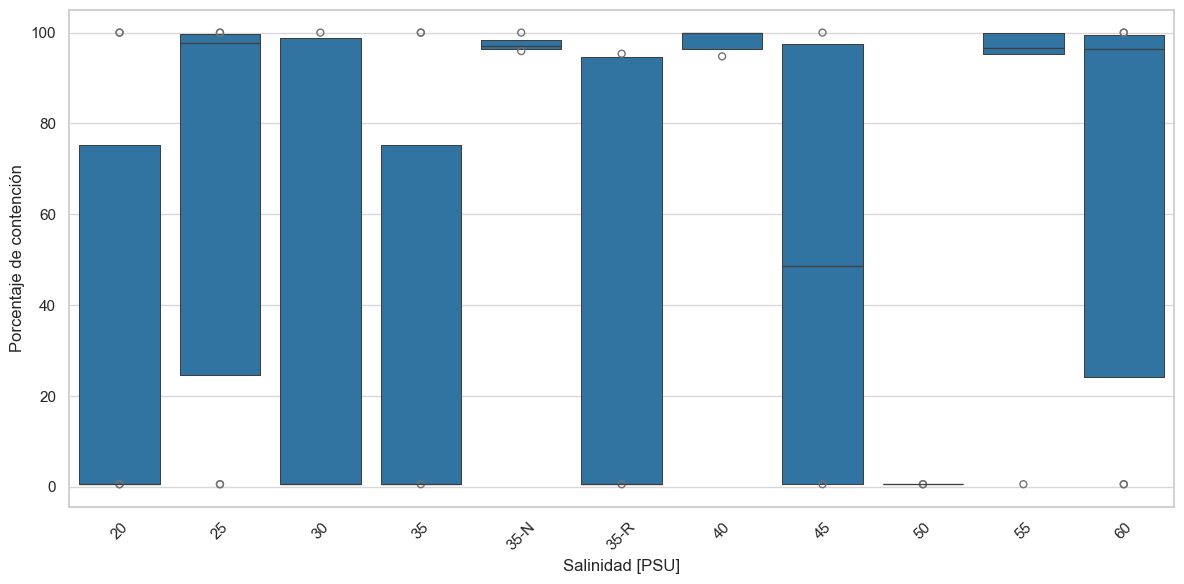

In [39]:
bins = np.arange(0, 105, 5) #o (0, 110, 10)

plt.figure(figsize=(12, 7))
counts, bins, patches = plt.hist(df_contencion['porcentaje_contencion'], bins=bins, color = paleta_colores['R'])

for count, patch in zip(counts, patches):
    if count > 0:
        plt.text(patch.get_x() + patch.get_width() / 2, count, int(count), ha='center', va='bottom')
plt.xlabel('Porcentaje de contención', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.xticks(bins, rotation=45)
plt.grid(visible=False)
plt.tight_layout()
guardar_figura('histograma_porcentajes_contencion_OU', 'porcentajes_contencion')

plt.figure(figsize=(12, 6))
sns.boxenplot(data=df_contencion, x='salinidad_ordenada', y='porcentaje_contencion', color = paleta_colores['R'])
plt.xlabel('Salinidad [PSU]')
plt.ylabel('Porcentaje de contención')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
guardar_figura('boxplot_porcentaje_contencion_por_salinidad_OU', 'porcentajes_contencion')
plt.show()

Figura guardada en: C:\Users\franc\Desktop\Para informe\porcentajes_contencion\boxplot_porcentaje_contencion_por_salinidad_OU_BUENOS.png


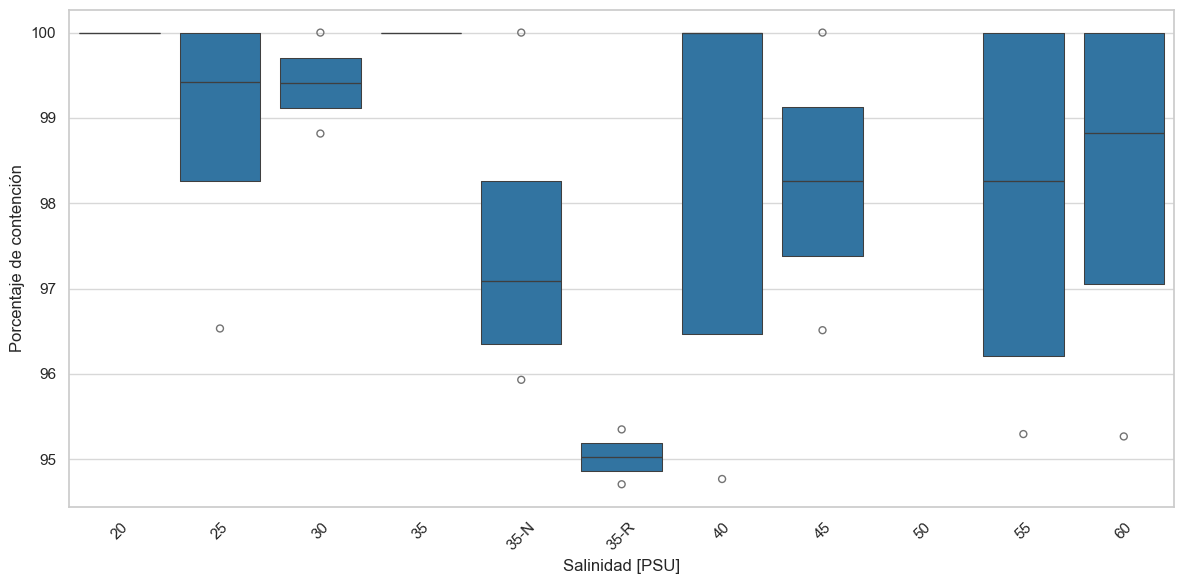

In [40]:
df_contencion2 = df_contencion[df_contencion['porcentaje_contencion'] > 80]
plt.figure(figsize=(12, 6))
sns.boxenplot(data=df_contencion2, x='salinidad_ordenada', y='porcentaje_contencion', color = paleta_colores['R'])
plt.xlabel('Salinidad [PSU]')
plt.ylabel('Porcentaje de contención')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
guardar_figura('boxplot_porcentaje_contencion_por_salinidad_OU_BUENOS', 'porcentajes_contencion')
plt.show()

# De acá pa abajo olvidar

In [41]:
# contencion_buenos = df_contencion[df_contencion.porcentaje_contencion > 75]
# contencion_buenos

# print(len(df_contencion) - len(contencion_buenos)) #cuántos mueren

In [42]:
# print(filtro)

In [43]:
# parametros_buenos = contencion_buenos.merge(filtro, how='left', on='id')
# parametros_buenos

In [ ]:
# fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

# #alpha
# sns.scatterplot(data=parametros_buenos, x='salinidad_ordenada_x', y='alpha', ax=axs[0])#, hue = 'mejor_por_logL')
# axs[0].set_title('alpha por grupo')
# axs[0].set_ylabel('alpha')

# #mu
# sns.scatterplot(data=parametros_buenos, x='salinidad_ordenada_x', y='mu', ax=axs[1])#, hue = 'mejor_por_logL')
# axs[1].set_title('mu por grupo')
# axs[1].set_ylabel('mu')

# #sigma
# sns.scatterplot(data=parametros_buenos, x='salinidad_ordenada_x', y='sigma', ax=axs[2])#, hue = 'mejor_por_logL')
# axs[2].set_title('sigma por grupo')
# axs[2].set_ylabel('sigma')

# axs[0].tick_params(axis='x', rotation=90)
# axs[1].tick_params(axis='x', rotation=90)
# axs[2].tick_params(axis='x', rotation=90)

# plt.tight_layout()
# #guardar_figura(f'parametros-{grupo}', 'plot_parametros_CIR')
# plt.show()

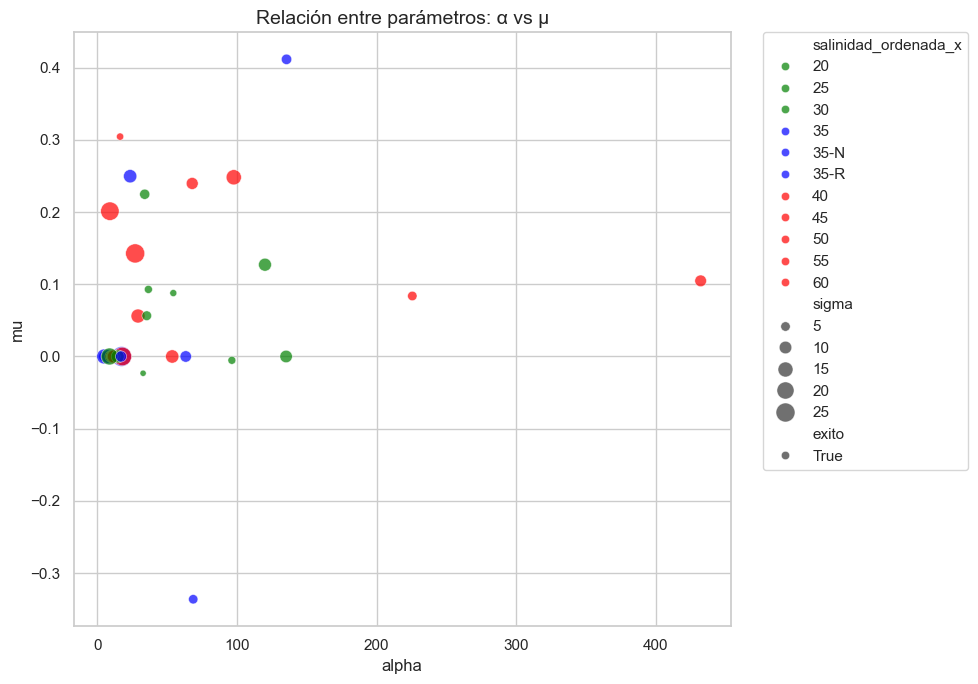

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns


# # Configuración de estilo
# sns.set(style="whitegrid")
# paleta_salinidad = {
#     "35-N": "blue",
#     "35-R": "blue",
#     "35": "blue",
#     "20": "green",
#     "25": "green",
#     "30": "green",
#     "40": "red",
#     "45": "red",
#     "50": "red",
#     "55": "red",
#     "60": "red"
# }
# # Gráfico de dispersión
# plt.figure(figsize=(10, 7))
# scatter = sns.scatterplot(
#     data=parametros_buenos,
#     x="alpha",
#     y="mu",
#     hue="salinidad_ordenada_x",       # Color por salinidad
#     size="sigma",          # Tamaño proporcional a sigma
#     style="exito",         # Forma del marcador según éxito
#     sizes=(20, 200),       # Rango de tamaños de puntos
#     alpha=0.7,
#     palette=paleta_salinidad
# )

# # Ajustes de leyenda y título
# plt.title("Relación entre parámetros: α vs μ", fontsize=14)
# plt.xlabel("alpha", fontsize=12)
# plt.ylabel("mu", fontsize=12)
# plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)  # leyenda afuera
# plt.tight_layout()
# plt.show()


### Respaldo código anterior

In [ ]:
# para hacerlos de a uno

# especie     = 'LA'
# tratamiento = 'R'
# nivel_salinidad   = 'alta'
# df_grp = filtrar_grupo(df, especie, tratamiento, nivel_salinidad)
# trayectorias, ids = extraer_trayectorias(df_grp, variable)
# parametros_grupo = df_grp.groupby('id')[['alpha_hat', 'mu_hat', 'sigma_hat']].first().reset_index()
# parametros_grupo = parametros_grupo.round(6)
# print(parametros_grupo)
# param_dict = parametros_grupo.set_index('id')[['alpha_hat', 'mu_hat', 'sigma_hat']].to_dict('index')

# resultados = []
# for id_tray, (data, dt) in zip(ids, trayectorias):
#     initial_guess = list(param_dict[id_tray].values())
    
#     res = minimize(
#         fun=logverosimilitud_OU,
#         x0=initial_guess,
#         args=(data, dt),
#         method='Nelder-Mead'
#     )
    
#     # if hasattr(res, 'hess_inv'):
#     #     try:
#     #         cov_matrix = res.hess_inv.todense() if hasattr(res.hess_inv, 'todense') else res.hess_inv
#     #         std_errors = np.sqrt(np.diag(cov_matrix))
#     #     except Exception:
#     #         std_errors = [np.nan] * len(res.x)
            
#     resultados.append({
#         'id': id_tray,
#         'alpha': res.x[0],
#         'mu': res.x[1],
#         'sigma': res.x[2],
#         # 'error_alpha': std_errors[0],
#         # 'error_mu': std_errors[1],
#         # 'error_sigma': std_errors[2],
#         'valor_funcion': res.fun,
#         'exito': res.success,
#         'mensaje': res.message
#     })


# df_resultados = pd.DataFrame(resultados)
# #df_resultados['error_total'] = df_resultados['error_alpha'] + df_resultados['error_mu'] + df_resultados['error_sigma']
# #cuantificación de la cobertura de las bandas con simulaciones de parámetros de cada fila
# def cobertura_grupo(alpha, mu, sigma, trayectorias, M=300):
#     coberturas = []
#     for data, dt in trayectorias:
#         r0 = data[0]
#         N  = len(data) - 1
#         sims = np.stack([
#             simular_OU(N, dt, alpha, mu, sigma, r0)
#             for _ in range(M)
#         ])
#         lower5, upper95 = np.percentile(sims, [5,95], axis=0)
#         cov_i = np.mean((data >= lower5) & (data <= upper95))
#         coberturas.append(cov_i)
#     return np.mean(coberturas)

# trayectorias_del_grupo = trayectorias

# def _calc_cov(row):
#     return cobertura_grupo(
#         row['alpha'], row['mu'], row['sigma'],
#         trayectorias_del_grupo,
#         M=300
#     )

# df_resultados['cobertura'] = df_resultados.apply(_calc_cov, axis=1)

# mejor_cobertura = df_resultados.loc[df_resultados['cobertura'].idxmax()]
# print("Parámetros elegidos por cobertura:", mejor_cobertura[['alpha','mu','sigma']])
# print("Mejor cobertura grupal:", mejor_cobertura['cobertura'])

# mejor_logL = df_resultados.loc[df_resultados['valor_funcion'].idxmin()]
# print("Parámetros elegidos por log-L:", mejor_logL[['alpha','mu','sigma','valor_funcion']])
# print("Mejor valor de la logverosimilitud:", mejor_logL['valor_funcion'])
# #estudio de los parámetros encontrados minimizando la logverosimilitud
# media_alpha = df_resultados['alpha'].mean()
# media_mu = df_resultados['mu'].mean()
# media_sigma = df_resultados['sigma'].mean()

# std_alpha = df_resultados['alpha'].std()
# std_mu = df_resultados['mu'].std()
# std_sigma = df_resultados['sigma'].std()


In [ ]:
# df_grp_unique = df_grp.drop_duplicates(subset='id')
# df_merged = pd.merge(df_resultados, df_grp_unique[['id', 'salinidad']], on='id')
# df_long = pd.melt(df_merged, id_vars=['id', 'salinidad'], value_vars=['alpha', 'mu', 'sigma'],
#                   var_name='parametro', value_name='valor')

# plt.figure(figsize=(10, 6))
# sns.boxplot(data=df_long, x='parametro', y='valor', color='lightgray')
# sns.stripplot(data=df_long, x='parametro', y='valor', hue='salinidad', dodge=True, jitter=True, palette='Set2')

# for origen, fila, color, label in zip(
#     ['mejor_cobertura', 'mejor_logL'],
#     [mejor_cobertura, mejor_logL],
#     ['red', 'blue'],
#     ['Cobertura óptima', 'Log-verosimilitud óptima']
# ):
#     for param in ['alpha', 'mu', 'sigma']:
#         plt.scatter(x=param, y=fila[param], color=color, s=100, edgecolor='black', label=label)

# handles, labels = plt.gca().get_legend_handles_labels()
# by_label = dict(zip(labels, handles))
# plt.legend(by_label.values(), by_label.keys(), bbox_to_anchor=(1.05, 1), loc='upper left')
# plt.title('Distribución de parámetros por salinidad con puntos óptimos destacados')
# plt.tight_layout()
# plt.savefig("boxplot_parametros_salinidad.png")
# plt.show()

In [ ]:
# #simulacion por logL
# alpha_sim1 = mejor_logL['alpha']
# mu_sim1 = mejor_logL['mu']
# sigma_sim1 = mejor_logL['sigma']

# evaluar_estimadores_OU_paper(
#     simular_OU=simular_OU,
#     trayectorias=trayectorias,
#     dt=dt,
#     alpha=alpha_sim1,
#     mu=mu_sim1,
#     sigma=sigma_sim1,
#     variable=variable,
#     df_grp=df_grp,
#     especie=especie,
#     tratamiento=tratamiento,
#     salinidad=nivel_salinidad,
#     M=1000
# )


In [ ]:
# #simulacion por cobertura
# alpha_sim2 = mejor_cobertura['alpha']
# mu_sim2 = mejor_cobertura['mu']
# sigma_sim2 = mejor_cobertura['sigma']

# evaluar_estimadores_OU_paper(
#     simular_OU=simular_OU,
#     trayectorias=trayectorias,
#     dt=dt,
#     alpha=alpha_sim2,
#     mu=mu_sim2,
#     sigma=sigma_sim2,
#     variable=variable,
#     df_grp=df_grp,
#     especie=especie,
#     tratamiento=tratamiento,
#     salinidad=nivel_salinidad,
#     M=1000
# )


In [ ]:
# #igual se plotean todas las demás por si acaso, podemos escoger otros parámetros

# for index, row in df_resultados.iterrows():
#     alpha_sim = row['alpha']
#     mu_sim = row['mu']
#     sigma_sim = row['sigma']
#     id_actual = row['id']
    
#     resultado = evaluar_estimadores_OU_paper(
#         simular_OU=simular_OU,
#         trayectorias=trayectorias,
#         dt=dt,
#         alpha=alpha_sim,
#         mu=mu_sim,
#         sigma=sigma_sim,
#         variable=variable,
#         df_grp=df_grp,
#         especie=especie,
#         tratamiento=tratamiento,
#         salinidad=nivel_salinidad,
#         M=1000)

#     print(f"ID {id_actual}")


Repetir esto para todos los grupos y guardar resultados. Si luego quiero arreglar consistencia entre colores, modificar este cuadernillo o funciones auxiliares y correr todo again!